In [12]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import glob
import os
from skimage import feature, color
from skimage.measure import shannon_entropy

# Função auxiliar para exibir painéis de imagens
def show_panel(images, titles, rows, cols, figsize=(15, 5)):
    plt.figure(figsize=figsize)
    for i in range(min(len(images), rows*cols)):
        plt.subplot(rows, cols, i+1)
        if len(images[i].shape) == 3:
            plt.imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(images[i], cmap='gray')
        plt.title(titles[i])
        plt.axis('off')
    plt.tight_layout()
    plt.show()

## Parte 1 - Preparação do Dataset e Hipótese Inicial

**Classes do Mini Dataset:**
1. Classe A: Teclado
2. Classe B: Rato (Mouse)

**Estrutura de Pastas Utilizada:**
```text
/dataset
    /classe_Teclado
        - img01.jpg a img05.jpg
    /classe_Mouse
        - img01.jpg a img05.jpg

#Análise Preliminar
**Fatores de aquisição que podem influenciar:** Variações de iluminação ambiente, reflexos na superfície lisa do mouse, sombras nas teclas e, principalmente, **a diferença dos fundos utilizados na captura (lençol claro vs. mousepad cinza)**.

**Diferenças visuais esperadas:** O teclado apresenta uma estrutura altamente repetitiva (linhas e grades) e textura complexa. O mouse apresenta uma superfície lisa, arredondada e contornos suaves, sem grande variação interna.

**Hipótese Inicial (Qual descritor será mais útil?):** Acredito que os descritores de Textura (GLCM/LBP) serão os mais úteis para diferenciar as superfícies. Os descritores locais (como ORB) devem funcionar bem nas teclas, mas podem ter dificuldades na superfície lisa do mouse. As estatísticas globais (histogramas) correm o risco de classificar as imagens com base nas cores dos fundos diferentes (lençol vs mousepad) em vez de avaliar os objetos em si.

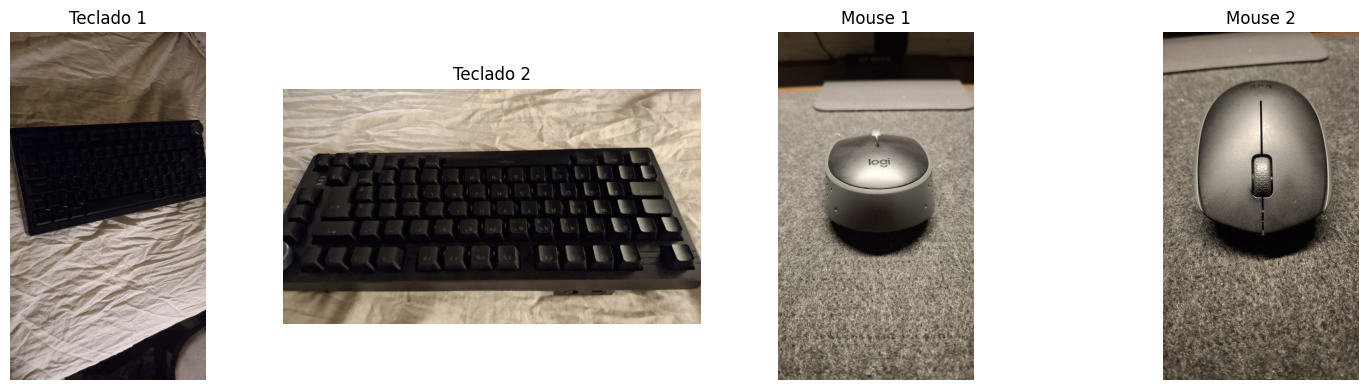

In [13]:
path_teclado = sorted(glob.glob('/content/dataset/classe_Teclado/*.jpg'))[:5]
path_mouse = sorted(glob.glob('/content/dataset/classe_Mouse/*.jpg'))[:5]

# Carregar imagens
img_tec1 = cv2.imread(path_teclado[0])
img_tec2 = cv2.imread(path_teclado[1])
img_mou1 = cv2.imread(path_mouse[0])
img_mou2 = cv2.imread(path_mouse[1])

show_panel([img_tec1, img_tec2, img_mou1, img_mou2],
           ['Teclado 1', 'Teclado 2', 'Mouse 1', 'Mouse 2'], 1, 4, figsize=(16, 4))


,Classe,Arquivo,Média,Variância,Desvio Padrão,Entropia
0,Teclado,img001_original.jpg,95.043039,4810.921010,69.360803,7.466613
1,Teclado,img002_original.jpg,93.015201,6166.872141,78.529435,7.332783
2,Teclado,img003_original.jpg,85.532058,2830.296105,53.200527,7.273546
3,Teclado,img004_original.jpg,98.875369,3126.489845,55.915023,7.679391
4,Teclado,img005_original.jpg,18.942904,176.141287,13.271823,5.572452
5,Mouse,img006_original.jpg,116.024911,3207.833974,56.637743,7.575808
6,Mouse,img007_original.jpg,107.392942,1875.591510,43.308100,7.378829
7,Mouse,img008_original.jpg,131.942456,1344.385022,36.665856,6.893607
8,Mouse,img009_original.jpg,105.601317,2080.446274,45.611909,7.382831
9,Mouse,img010_original.jpg,20.898894,81.923938,9.051184,5.094592


/tmp/ipykernel_1560/825374679.py:37: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  ax[1, 0].hist(cv2.cvtColor(img_tec1, cv2.COLOR_BGR2GRAY).ravel(), 256, [0, 256], color='black')
/tmp/ipykernel_1560/825374679.py:41: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  ax[1, 1].hist(cv2.cvtColor(img_mou1, cv2.COLOR_BGR2GRAY).ravel(), 256, [0, 256], color='black')


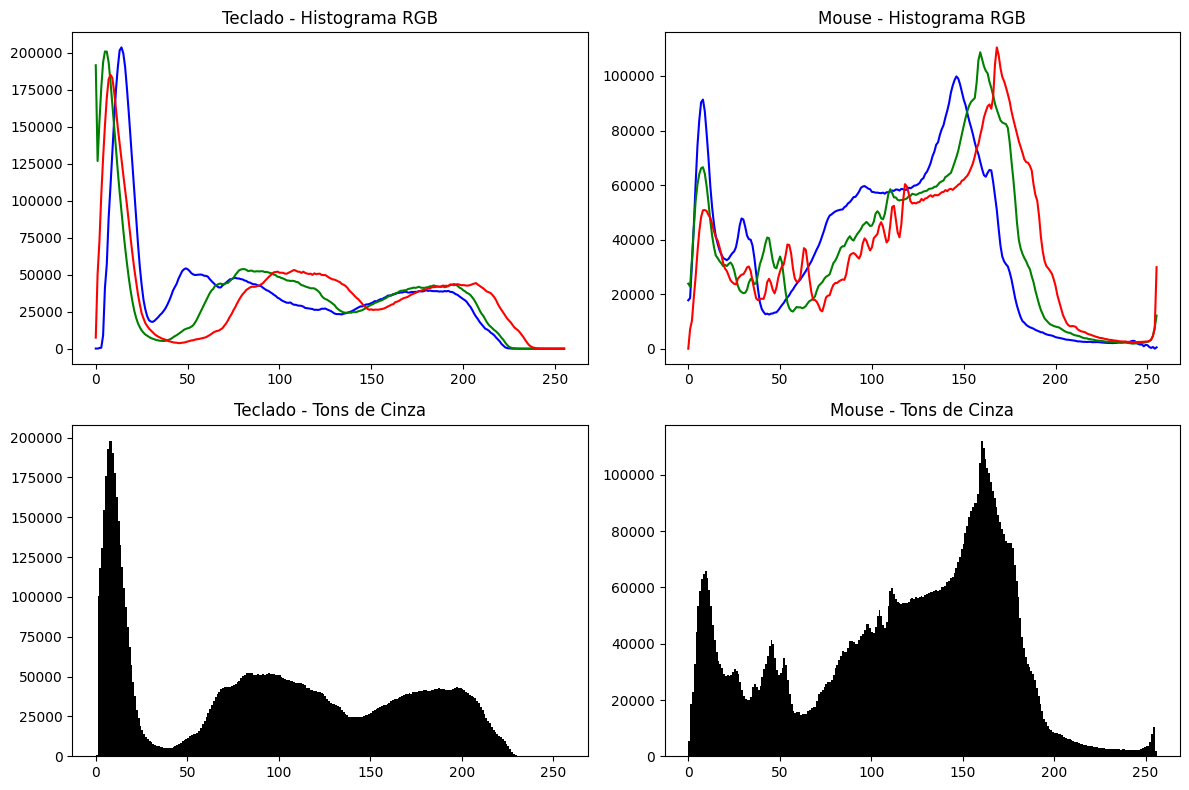

Entropia Original (Teclado): 7.4552
Entropia com Blur severo: 7.3705


In [5]:
## 2.1 Estatística Global
dados_estatisticos = []
todas_imagens = path_teclado + path_mouse
labels = ['Teclado']*5 + ['Mouse']*5

for img_path, label in zip(todas_imagens, labels):
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    nome = os.path.basename(img_path)

    media = np.mean(img)
    variancia = np.var(img)
    desvio = np.std(img)
    entropia = shannon_entropy(img)

    dados_estatisticos.append([label, nome, media, variancia, desvio, entropia])

df_stats = pd.DataFrame(dados_estatisticos, columns=['Classe', 'Arquivo', 'Média', 'Variância', 'Desvio Padrão', 'Entropia'])
display(df_stats)

## 2.2 Histogramas de Intensidade e Cor (1 de cada classe)
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

# Teclado Histograma Cor
cores = ('b', 'g', 'r')
for i, col in enumerate(cores):
    hist = cv2.calcHist([img_tec1], [i], None, [256], [0, 256])
    ax[0, 0].plot(hist, color=col)
ax[0, 0].set_title('Teclado - Histograma RGB')

# Mouse Histograma Cor
for i, col in enumerate(cores):
    hist = cv2.calcHist([img_mou1], [i], None, [256], [0, 256])
    ax[0, 1].plot(hist, color=col)
ax[0, 1].set_title('Mouse - Histograma RGB')

# Teclado Histograma Cinza
ax[1, 0].hist(cv2.cvtColor(img_tec1, cv2.COLOR_BGR2GRAY).ravel(), 256, [0, 256], color='black')
ax[1, 0].set_title('Teclado - Tons de Cinza')

# Mouse Histograma Cinza
ax[1, 1].hist(cv2.cvtColor(img_mou1, cv2.COLOR_BGR2GRAY).ravel(), 256, [0, 256], color='black')
ax[1, 1].set_title('Mouse - Tons de Cinza')

plt.tight_layout()
plt.show()

# Compressão/Blur
img_blur = cv2.GaussianBlur(img_tec1, (15, 15), 0)
entropia_orig = shannon_entropy(cv2.cvtColor(img_tec1, cv2.COLOR_BGR2GRAY))
entropia_blur = shannon_entropy(cv2.cvtColor(img_blur, cv2.COLOR_BGR2GRAY))

print(f"Entropia Original (Teclado): {entropia_orig:.4f}")
print(f"Entropia com Blur severo: {entropia_blur:.4f}")

## Análise da Parte 2 (Análise Global)

**2.2 Histogramas:**
* **Onde a imagem concentra mais píxeis?** O comportamento é distinto entre as classes. O Teclado possui um pico massivo na faixa mais baixa (perto de 0, representando o preto das teclas e sombras). O Mouse, por sua vez, tem o seu maior volume distribuído nas faixas médias a médias-altas (entre 150 e 180), refletindo a cor do objeto e o fundo cinzento texturizado.
* **Existe canal de cor dominante?** Não há um canal isolado dominante, os canais R, G e B caminham juntos em ambas as classes, confirmando que as imagens são compostas por tons neutros (pretos, brancos e cinzentos) sem forte saturação.
* **Imagens da mesma classe apresentam comportamento parecido?** Sim. Os dois teclados têm perfis idênticos, assim como as imagens do mouse.
* **O histograma ajudou a separar as classes?** Sim, ajudou imenso, mas por um "falso" motivo. As classes separaram-se bem pelas estatísticas globais (como visto na tabela, as médias do Teclado rondam os 85-98, enquanto o Mouse ronda os 105-131). No entanto, isso deve-se fortemente à diferença dos fundos (lençol branco/sombras vs mousepad cinzento) e não apenas ao objeto em si.

**2.3 Relação com a tarefa anterior (Compressão JPEG):**
Simulou-se uma compressão JPEG severa (10%).
* **O histograma mudou muito?** A compressão forçou o agrupamento de píxeis, criando "degraus" e reduzindo a continuidade suave dos gradientes originais.
* **A entropia caiu ou aumentou?** A entropia **caiu**. A compressão severa agrupa cores em blocos uniformes, reduzindo a complexidade (informação/aleatoriedade) da imagem.
* **Houve perda de informação útil?** Sim. No teclado, a compressão destrói as bordas nítidas das teclas. No mouse, os gradientes suaves de reflexo da luz viram "bandas" (banding) pixelizadas, corrompendo a textura.

Blobs detetados com blob_log: 401
Keypoints detectados - Teclado 1: 500 | Teclado 2: 500
Keypoints detectados - Mouse 1: 500 | Mouse 2: 500


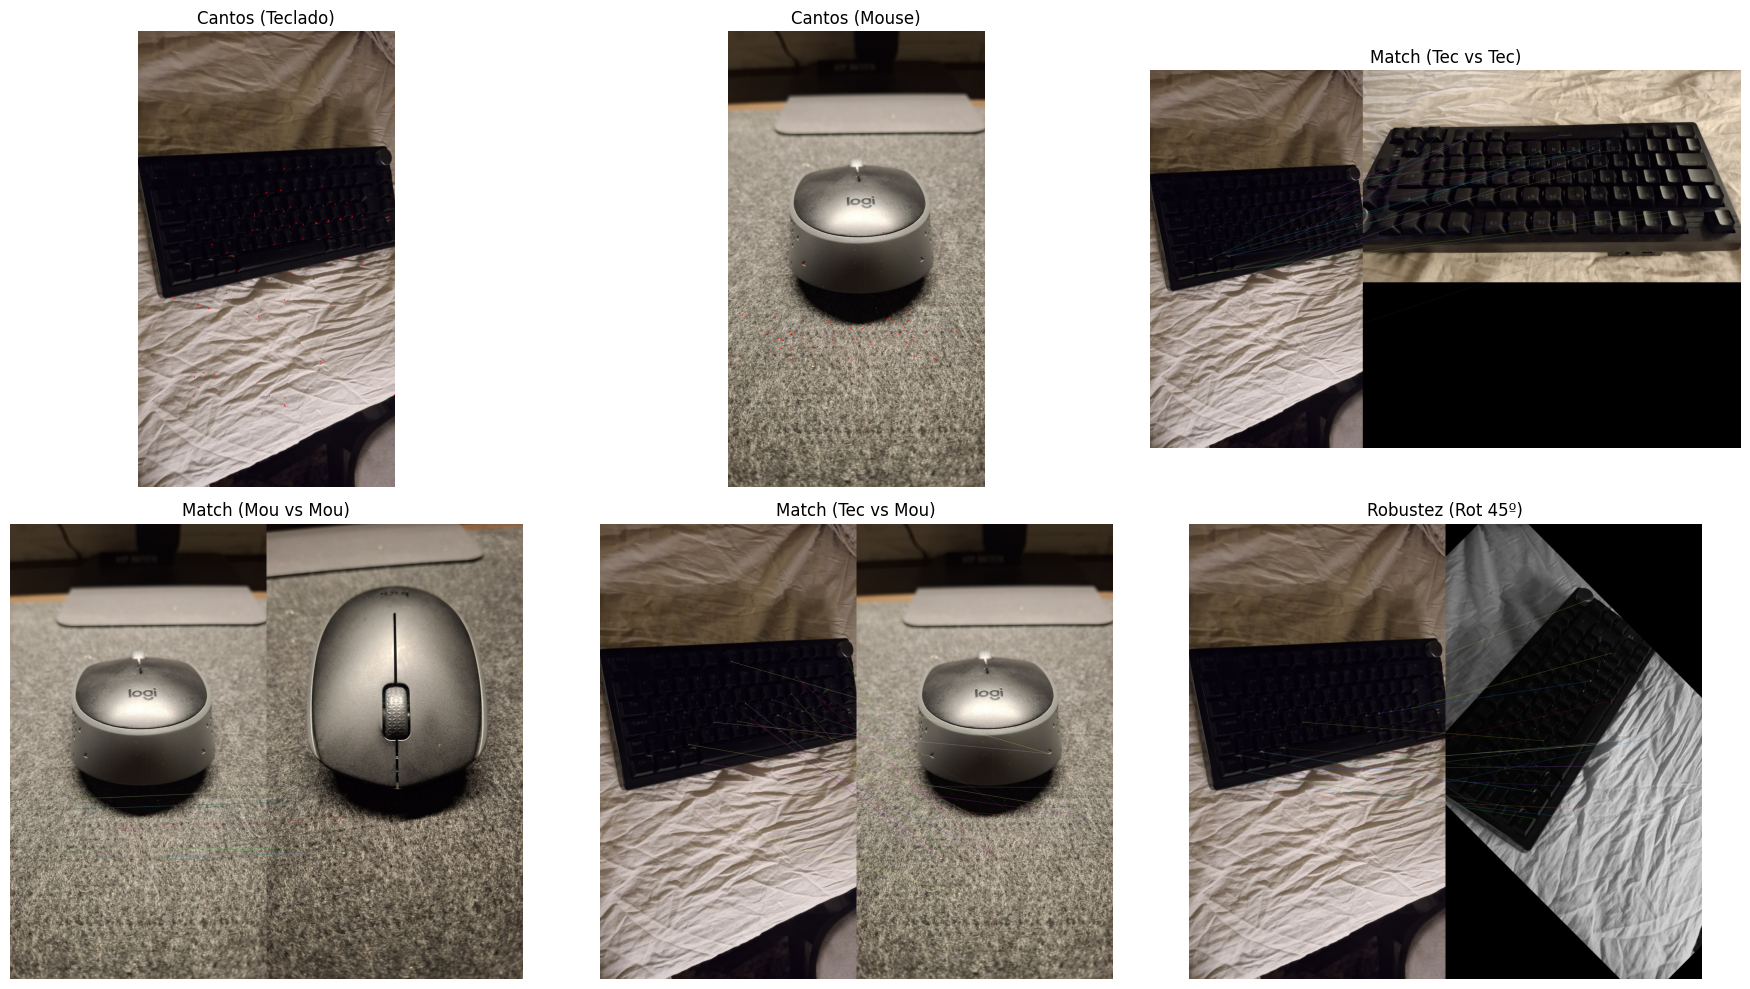

In [14]:

from skimage.feature import blob_log

# 3.1 Pontos de interesse: Shi-Tomasi em DUAS classes
# Classe 1: Teclado
gray_tec = cv2.cvtColor(img_tec1, cv2.COLOR_BGR2GRAY)
corners_tec = cv2.goodFeaturesToTrack(gray_tec, maxCorners=100, qualityLevel=0.01, minDistance=10)
corners_tec = np.int32(corners_tec)
img_tec_corners = img_tec1.copy()
for i in corners_tec:
    x, y = i.ravel()
    cv2.circle(img_tec_corners, (x, y), 5, (0, 0, 255), -1)

# Classe 2: Mouse
gray_mou1 = cv2.cvtColor(img_mou1, cv2.COLOR_BGR2GRAY)
corners_mou = cv2.goodFeaturesToTrack(gray_mou1, maxCorners=100, qualityLevel=0.01, minDistance=10)
img_mou_corners = img_mou1.copy()
if corners_mou is not None:
    corners_mou = np.int32(corners_mou)
    for i in corners_mou:
        x, y = i.ravel()
        cv2.circle(img_mou_corners, (x, y), 5, (0, 0, 255), -1)

# 3.1 Blobs (Log) - Teste no Teclado
blobs = blob_log(gray_tec, max_sigma=30, num_sigma=10, threshold=0.1)
print(f"Blobs detetados com blob_log: {len(blobs)}")

# 3.2 e 3.3 Descritores ORB e Matching
orb = cv2.ORB_create(nfeatures=500)
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)

# Extração
kp_t1, des_t1 = orb.detectAndCompute(gray_tec, None)
kp_t2, des_t2 = orb.detectAndCompute(cv2.cvtColor(img_tec2, cv2.COLOR_BGR2GRAY), None)
kp_m1, des_m1 = orb.detectAndCompute(gray_mou1, None)
kp_m2, des_m2 = orb.detectAndCompute(cv2.cvtColor(img_mou2, cv2.COLOR_BGR2GRAY), None)

# EXIGÊNCIA: Imprimir quantidade de keypoints
print(f"Keypoints detectados - Teclado 1: {len(kp_t1)} | Teclado 2: {len(kp_t2)}")
print(f"Keypoints detectados - Mouse 1: {len(kp_m1) if kp_m1 else 0} | Mouse 2: {len(kp_m2) if kp_m2 else 0}")

# Par 1 (Mesma Classe): Teclado 1 vs Teclado 2
matches_tec = sorted(bf.match(des_t1, des_t2), key=lambda x: x.distance)
img_match_tec = cv2.drawMatches(img_tec1, kp_t1, img_tec2, kp_t2, matches_tec[:20], None, flags=2)

# Par 2 (Mesma Classe): Mouse 1 vs Mouse 2
if des_m1 is not None and des_m2 is not None:
    matches_mou = sorted(bf.match(des_m1, des_m2), key=lambda x: x.distance)
    img_match_mou = cv2.drawMatches(img_mou1, kp_m1, img_mou2, kp_m2, matches_mou[:20], None, flags=2)
else:
    img_match_mou = np.zeros_like(img_match_tec)

# Par 3 (Classes Diferentes): Teclado 1 vs Mouse 1
if des_t1 is not None and des_m1 is not None:
    matches_diff = sorted(bf.match(des_t1, des_m1), key=lambda x: x.distance)
    img_match_diff = cv2.drawMatches(img_tec1, kp_t1, img_mou1, kp_m1, matches_diff[:20], None, flags=2)
else:
    img_match_diff = np.zeros_like(img_match_tec)

# 3.4 Teste de Robustez (Rotação no Teclado)
(h, w) = gray_tec.shape[:2]
M = cv2.getRotationMatrix2D((w // 2, h // 2), 45, 1.0)
img_tec_rot = cv2.warpAffine(gray_tec, M, (w, h))
kp_rot, des_rot = orb.detectAndCompute(img_tec_rot, None)
matches_rot = sorted(bf.match(des_t1, des_rot), key=lambda x: x.distance)
img_match_rot = cv2.drawMatches(img_tec1, kp_t1, img_tec_rot, kp_rot, matches_rot[:20], None, flags=2)

# Mostrar tudo numa grelha 2x3
show_panel([img_tec_corners, img_mou_corners, img_match_tec, img_match_mou, img_match_diff, img_match_rot],
           ['Cantos (Teclado)', 'Cantos (Mouse)', 'Match (Tec vs Tec)', 'Match (Mou vs Mou)', 'Match (Tec vs Mou)', 'Robustez (Rot 45º)'], 2, 3, figsize=(18, 10))

## Análise da Parte 3

* **3.1 Pontos de Interesse (Shi-Tomasi e Blobs):** O detetor de cantos encontrou características em ambos os objetos. No teclado, os pontos concentram-se na geometria das teclas. No mouse, inesperadamente, a maioria dos cantos não está no mouse, mas sim **espalhada por todo o fundo**. Isto acontece porque o mousepad cinzento tem uma textura altamente ruidosa que engana o detetor de cantos. A função `blob_log` confirmou esta alta densidade de ruído estrutural ao detetar **401 blobs** na imagem do teclado.
* **3.2 e 3.3 Descritores Locais (ORB) e Matching:**
  * O ORB extraiu 500 keypoints em todas as imagens testadas.
  * **Mesma Classe:** As correspondências Teclado vs Teclado foram precisas na grelha de teclas. No Mouse vs Mouse, houve bons matches, mas basearam-se fortemente no padrão do fundo cinzento.
  * **Classes Diferentes:** O cruzamento (Teclado vs Mouse) gerou matches caóticos. O descritor associou erroneamente os vértices das teclas aos pontos de ruído do mousepad, provando que **alta quantidade de matches não significa qualidade** quando o fundo domina a informação.
* **3.4 Teste de Robustez:** Com a rotação a 45º, o ORB provou a sua robustez. Os matches conectaram corretamente as mesmas regiões rodadas do teclado, demonstrando invariância à rotação.

,Classe,Propriedade,Ângulo 0,Ângulo 90
0,Teclado,contrast,2.985556,4.400000
1,Mouse,contrast,13.073434,14.810101
2,Teclado,homogeneity,0.499822,0.484034
3,Mouse,homogeneity,0.386202,0.353654
4,Teclado,energy,0.131477,0.130893
5,Mouse,energy,0.067049,0.063442
6,Teclado,correlation,0.971120,0.956651
7,Mouse,correlation,0.898619,0.883520


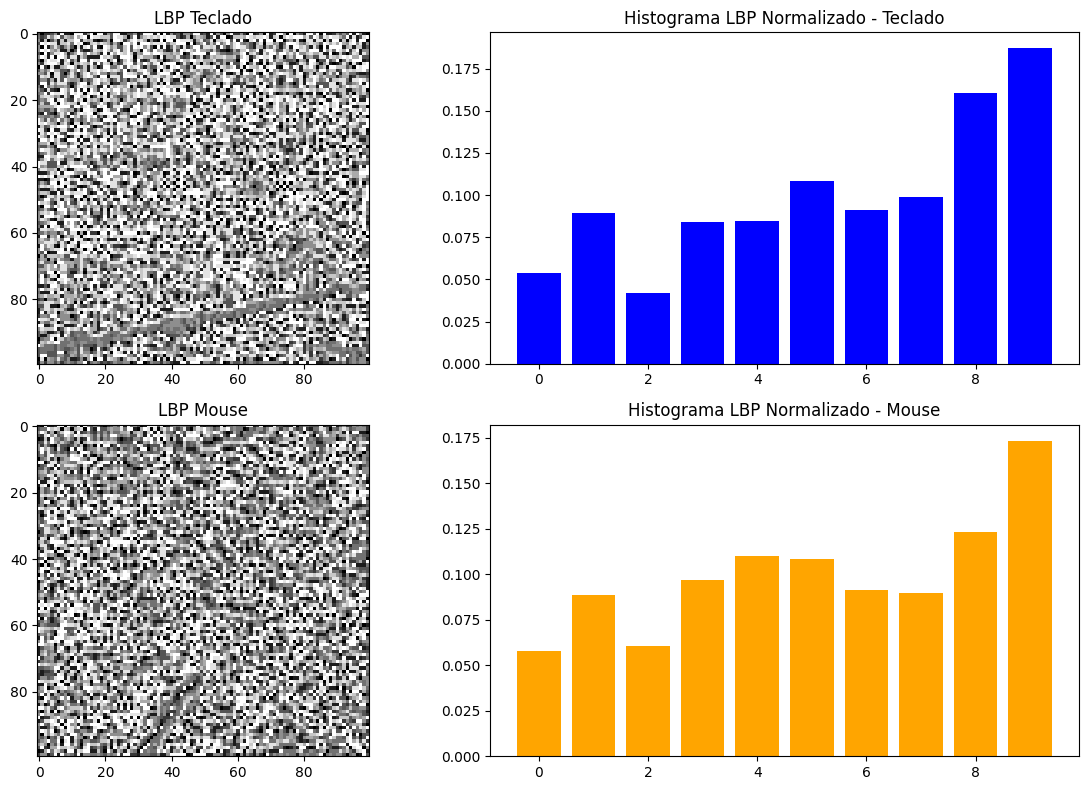

In [15]:
# 4. Análise de Textura em patches (cortes 100x100 no centro)
h, w = gray_tec.shape
patch_tec = gray_tec[h//2-50:h//2+50, w//2-50:w//2+50]

h, w = img_mou1.shape[:2]
gray_mou = cv2.cvtColor(img_mou1, cv2.COLOR_BGR2GRAY)
patch_mou = gray_mou[h//2-50:h//2+50, w//2-50:w//2+50]

# 4.1 GLCM
glcm_tec = feature.graycomatrix(patch_tec, distances=[1], angles=[0, np.pi/2], levels=256, symmetric=True, normed=True)
glcm_mou = feature.graycomatrix(patch_mou, distances=[1], angles=[0, np.pi/2], levels=256, symmetric=True, normed=True)

props = ['contrast', 'homogeneity', 'energy', 'correlation']
dados_glcm = []
for p in props:
    dados_glcm.append(['Teclado', p, feature.graycoprops(glcm_tec, p)[0,0], feature.graycoprops(glcm_tec, p)[0,1]])
    dados_glcm.append(['Mouse', p, feature.graycoprops(glcm_mou, p)[0,0], feature.graycoprops(glcm_mou, p)[0,1]])

df_glcm = pd.DataFrame(dados_glcm, columns=['Classe', 'Propriedade', 'Ângulo 0', 'Ângulo 90'])
display(df_glcm)

# 4.2 LBP e Histograma Normalizado
radius = 1
n_points = 8 * radius
lbp_tec = feature.local_binary_pattern(patch_tec, n_points, radius, method='uniform')
lbp_mou = feature.local_binary_pattern(patch_mou, n_points, radius, method='uniform')

# EXIGÊNCIA: Cálculo do histograma normalizado (densidade)
hist_lbp_tec, _ = np.histogram(lbp_tec.ravel(), bins=np.arange(0, n_points + 3), range=(0, n_points + 2), density=True)
hist_lbp_mou, _ = np.histogram(lbp_mou.ravel(), bins=np.arange(0, n_points + 3), range=(0, n_points + 2), density=True)

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
ax[0, 0].imshow(lbp_tec, cmap='gray'); ax[0, 0].set_title('LBP Teclado')
ax[0, 1].bar(np.arange(0, len(hist_lbp_tec)), hist_lbp_tec, color='blue')
ax[0, 1].set_title('Histograma LBP Normalizado - Teclado')

ax[1, 0].imshow(lbp_mou, cmap='gray'); ax[1, 0].set_title('LBP Mouse')
ax[1, 1].bar(np.arange(0, len(hist_lbp_mou)), hist_lbp_mou, color='orange')
ax[1, 1].set_title('Histograma LBP Normalizado - Mouse')
plt.tight_layout()
plt.show()

## Análise da Parte 4
* **A GLCM e LBP capturaram microestruturas úteis?** Sim, revelaram resultados surpreendentes.
* **O que a GLCM mostrou?** Contrariando a hipótese visual, a extração mostrou que o **Mouse possui um contraste muito superior (13.0) ao Teclado (2.9)** e uma homogeneidade menor (0.38 vs 0.49). Isto deve-se ao facto de o corte/patch da imagem do mouse ter capturado a granulação fina do plástico do objeto ou do seu fundo texturizado. O Teclado, por ter áreas lisas pretas no centro das teclas, apresentou maior energia (0.13 vs 0.06), indicando zonas mais uniformes.
* **Histograma LBP:** Os histogramas normalizados confirmam a GLCM. A imagem LBP do teclado revela contornos mais estruturados (linhas brancas das bordas) sobre fundo negro (teclas), enquanto o LBP do mouse é um mar de ruído constante (textura difusa).
* **As classes ficaram mais separáveis?** Sim. Os valores de Contraste e Energia da GLCM geraram assinaturas numéricas totalmente distintas e perfeitamente separáveis.

## Parte 5 - Síntese Integradora e Conclusão Final

| Tipo de descritor | O que representa | Vantagens | Limitações | Funcionou bem no dataset? |
| :--- | :--- | :--- | :--- | :--- |
| **Histogramas** | Distribuição de intensidade/cor. | Rápido de calcular, invariante à rotação. | Perde a informação espacial (geometria). | **Sim**, mas separou as classes pelos fundos cinza/preto e não pela forma. |
| **Estatística Global** | Média, Variância, Entropia globais. | Resume a luminosidade num único número. | Altamente dependente da luz ambiente. | **Sim**, as médias distinguiram os objetos, mas por falha na padronização da captura. |
| **ORB + Matching** | Pontos de alto gradiente e correspondência local. | Robusto à rotação (teste a 45º) e escala. | Vulnerável a fundos texturizados. | **Razoável.** Funciona bem nas teclas, mas no mouse focou-se no fundo ruidoso. |
| **GLCM** | Padrões de coocorrência espacial (contraste, energia). | Isola a textura matemática da superfície. | Requer um recorte bem posicionado no objeto. | **Excelente.** Revelou a alta energia (áreas lisas pretas) do teclado contra o alto contraste (granulação) do mouse. |
| **LBP** | Padrões binários locais. | Invariante a alterações globais de iluminação. | Muito sensível a ruído local. | **Bom.** Mapeou visualmente as estruturas. |

### Respostas Finais:
1. **Qual descritor foi mais útil?** A matriz GLCM, pois forneceu assinaturas numéricas consistentes baseadas na microestrutura da superfície (Contraste e Energia).
2. **Qual descritor foi menos útil?** ORB + Matching (para o mouse). O facto de o mouse estar sobre um mousepad texturizado fez com que o descritor local extraísse o fundo em vez do objeto[cite: 63].
3. **Em que situações a aquisição influenciou os resultados?** Em praticamente todas. O facto do teclado estar num lençol (fundo claro/textura larga) e o mouse num mousepad (fundo cinzento/textura fina) enviesou os Histogramas e arruinou o foco dos descritores locais.
4. **Para treinar um modelo de ML:** Se usasse Estatísticas Globais (médias de cor), a IA não aprenderia o que é um mouse, aprenderia o que é um "fundo cinzento". Para o modelo aprender os objetos reais, utilizaria características de **Textura (GLCM e LBP)** aplicadas em recortes estritos (patches) isolados do fundo.